# Assignment 2 · Task 1: Canada's Per-Capita Income with Gradient Descent

**Objective:** Predict Canada's per-capita income for **2020** from the single input feature `year` and the target `per capita income (US$)`.

**Approach:** This is a beginner-level, single-variable Linear Regression. The model parameters are learned by **full-batch Gradient Descent written from scratch with NumPy**. The model, feature scaling, and evaluation metrics do not use scikit-learn, a closed-form fit, or `np.polyfit`.

**Notebook roadmap:** inspect the real CSV → explore the time trend → make only justified cleaning decisions → use a chronological validation split → derive and run the gradient updates → compute validation metrics by hand → refit on all pre-2020 rows → predict 2020.

**Assignment source:** the PDF gives the Kaggle URL [Canada Per Capita Income](https://www.kaggle.com/datasets/gurdit559/canada-per-capita-income-single-variable-data-set/data) and identifies data.worldbank.org as the original source. The sandbox could not reach Kaggle directly. To execute this notebook, I used the same 47-row CSV through a public GitHub copy at [dfinke/PSKit](https://github.com/dfinke/PSKit/blob/5d91034c7178e3aa8ef021b624c3a08639df49e9/sampleCsv/canada_per_capita_income.csv) (Git blob `39dec17eb3c43752e335443304bf41a9efcd8184`; byte SHA-256 `953dfb3a0105366cc22f0db74edef33d850fdff0f83fbe24bd8c50d4dea1d207`). Its schema, range, and displayed values agree with the prior Assignment 1 inspection. The raw CSV is local-only and is not committed. For your own run, download the Kaggle file into `data/canada/` as described in `data/README.md`.

## 1. Setup and repository-relative data path

Import only the tools needed for data handling, numerical calculations, and plots. The repository-root search lets the notebook work when Jupyter is started from the repository root or one of its subfolders. No modeling library is imported.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True


def find_repo_root(start: Path) -> Path:
    """Walk upward until the repository's data/ and assignments/ folders are found."""
    for candidate in (start, *start.parents):
        if (candidate / "data").is_dir() and (candidate / "assignments").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not find the repository root. Start Jupyter from this repository "
        "or one of its subfolders."
    )


ROOT = find_repo_root(Path.cwd())
DATA_DIR = ROOT / "data" / "canada"
print("Repository root:", ROOT)
print("Dataset folder:", DATA_DIR)

Repository root: /home/user/ML-Course-Assignments
Dataset folder: /home/user/ML-Course-Assignments/data/canada


## 2. Load the CSV and take a first look

Read the actual CSV in `data/canada/`; `utf-8-sig` removes the optional UTF-8 byte-order mark found in this dataset. If there is no CSV, stop with download instructions rather than substituting generated data. If several CSV files are present, stop rather than silently choosing the wrong one.

In [2]:
csv_files = sorted(DATA_DIR.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(
        f"No CSV found in {DATA_DIR}. Download the dataset from the Kaggle link "
        "in the assignment PDF and extract it here. From the repository root, "
        "the Kaggle CLI command is:\n"
        "kaggle datasets download -d "
        "gurdit559/canada-per-capita-income-single-variable-data-set "
        "-p data/canada --unzip"
    )
if len(csv_files) != 1:
    raise ValueError(
        f"Expected exactly one CSV in {DATA_DIR}, but found: "
        f"{[path.name for path in csv_files]}. Keep only the assignment dataset there."
    )

csv_path = csv_files[0]
df_raw = pd.read_csv(csv_path, encoding="utf-8-sig")
df_raw.columns = [str(column).strip() for column in df_raw.columns]

print("CSV file:", csv_path.name)
print("Shape (rows, columns):", df_raw.shape)
print("First five rows:")
display(df_raw.head())
print("Last five rows:")
display(df_raw.tail())

CSV file: canada_per_capita_income.csv
Shape (rows, columns): (47, 2)
First five rows:


,year,per capita income (US$)
0,1970,3399.299037
1,1971,3768.297935
2,1972,4251.175484
3,1973,4804.463248
4,1974,5576.514583


Last five rows:


,year,per capita income (US$)
42,2012,42665.25597
43,2013,42676.46837
44,2014,41039.89360
45,2015,35175.18898
46,2016,34229.19363


## 3. Inspect columns, types, missing values, and duplicates

Confirm the feature and target from the CSV instead of inventing column names. Then inspect data types, nulls, duplicate rows, duplicate years, and the target's basic range. A year should appear at most once in this annual dataset.

In [3]:
print("Columns:", list(df_raw.columns))
print("\nData types:")
print(df_raw.dtypes)
print("\nDataFrame info:")
df_raw.info()

if len(df_raw.columns) != 2:
    raise ValueError(
        f"Expected the two columns described in the assignment PDF, got {len(df_raw.columns)}."
    )
year_matches = [column for column in df_raw.columns if "year" in column.lower()]
if len(year_matches) != 1:
    raise ValueError(f"Could not identify exactly one year column: {list(df_raw.columns)}")
year_col = year_matches[0]
target_col = next(column for column in df_raw.columns if column != year_col)

print(f"\nInput feature : {year_col!r} (calendar year)")
print(f"Target        : {target_col!r} (income in US dollars)")
print("\nMissing values per column:")
print(df_raw.isna().sum())
print("\nFully duplicated rows:", int(df_raw.duplicated().sum()))
print("Duplicated years:", int(df_raw[year_col].duplicated().sum()))
print("\nTarget summary:")
print(pd.to_numeric(df_raw[target_col], errors="coerce").describe())

Columns: ['year', 'per capita income (US$)']

Data types:
year                         int64
per capita income (US$)    float64
dtype: object

DataFrame info:
<class 'pandas.DataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   year                     47 non-null     int64  
 1   per capita income (US$)  47 non-null     float64
dtypes: float64(1), int64(1)
memory usage: 884.0 bytes

Input feature : 'year' (calendar year)
Target        : 'per capita income (US$)' (income in US dollars)

Missing values per column:
year                       0
per capita income (US$)    0
dtype: int64

Fully duplicated rows: 0
Duplicated years: 0

Target summary:
count       47.000000
mean     18920.137063
std      12034.679438
min       3399.299037
25%       9526.914515
50%      16426.725480
75%      27458.601420
max      42676.468370
Name: per capita income (US$), dtype

## 4. Exploratory data analysis: income over time

A time-ordered scatter plot is the most useful first view for this one-feature time series. It shows the long-run direction and whether a straight-line trend is plausible; the points are connected only to make the chronology easier to follow. The descriptive summary also gives the observed years and income scale.

Numeric rows available for this plot: 47 of 47
Descriptive statistics:


,year,per capita income (US$)
count,47.000000,47.000000
mean,1993.000000,18920.137063
std,13.711309,12034.679438
min,1970.000000,3399.299037
25%,1981.500000,9526.914515
50%,1993.000000,16426.725480
75%,2004.500000,27458.601420
max,2016.000000,42676.468370


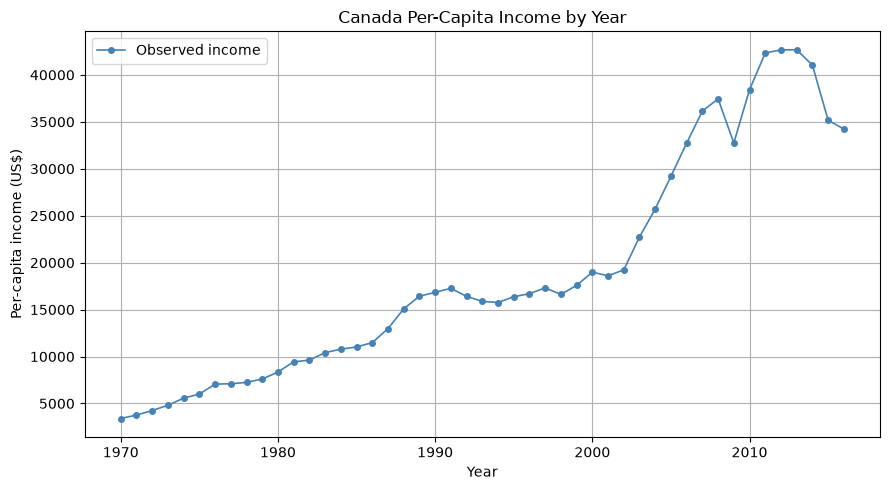

In [4]:
eda_data = df_raw[[year_col, target_col]].apply(pd.to_numeric, errors="coerce").dropna()
eda_data = eda_data.sort_values(year_col)
print(f"Numeric rows available for this plot: {len(eda_data)} of {len(df_raw)}")
print("Descriptive statistics:")
display(eda_data.describe())

fig, ax = plt.subplots()
ax.plot(
    eda_data[year_col],
    eda_data[target_col],
    marker="o",
    markersize=4,
    linewidth=1.2,
    color="steelblue",
    label="Observed income",
)
ax.set_title("Canada Per-Capita Income by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Per-capita income (US$)")
ax.ticklabel_format(style="plain", axis="y")
ax.legend()
plt.tight_layout()
plt.show()

**EDA interpretation:** income rises strongly over the full period, but the latest observations turn downward after the earlier growth. A straight line is a useful beginner model for the overall trend, but it cannot represent every bend. This is why a later-years holdout is important and why extrapolating to 2020 must be treated cautiously.

## 5. Clean only actual data problems

The dataset should contain numeric annual years and positive income values. Convert the two selected columns to numeric, identify and report invalid rows, remove only rows that cannot be used, remove exact duplicate rows if any, and reject conflicting duplicate years rather than arbitrarily averaging them. Sort chronologically. No income outliers are removed: in a time series, an unusually high or low year can be real economic behavior, not a data error.

In [5]:
df = df_raw[[year_col, target_col]].copy()
df[year_col] = pd.to_numeric(df[year_col], errors="coerce")
df[target_col] = pd.to_numeric(df[target_col], errors="coerce")

finite_rows = np.isfinite(df[[year_col, target_col]].to_numpy(dtype=float)).all(axis=1)
valid_rows = df[[year_col, target_col]].notna().all(axis=1).to_numpy() & finite_rows
invalid_count = int((~valid_rows).sum())
print("Rows with missing, non-numeric, or non-finite values:", invalid_count)
if invalid_count:
    print("Rows excluded because they cannot be used:")
    display(df.loc[~valid_rows])
    df = df.loc[valid_rows].copy()

exact_duplicates = int(df.duplicated().sum())
print("Exact duplicate rows:", exact_duplicates)
if exact_duplicates:
    df = df.drop_duplicates(keep="first").copy()

if df.empty:
    raise ValueError("No usable rows remain after numeric checks.")
if df[year_col].duplicated().any():
    raise ValueError(
        "More than one different record has the same year. Resolve the duplicate "
        "using the source data before fitting this one-row-per-year example."
    )
if not np.equal(df[year_col].to_numpy(), np.floor(df[year_col].to_numpy())).all():
    raise ValueError("The year column contains non-integer values.")
df[year_col] = df[year_col].astype(int)
if (df[target_col] <= 0).any():
    raise ValueError("Per-capita income should be positive; inspect the source values.")

df = df.sort_values(year_col).reset_index(drop=True)
all_years = set(df[year_col].tolist())
expected_years = set(range(int(df[year_col].min()), int(df[year_col].max()) + 1))
missing_years = sorted(expected_years - all_years)

print(f"Rows retained: {len(df)} of {len(df_raw)}")
print(f"Year range: {df[year_col].min()}–{df[year_col].max()}")
print("Missing years within that range:", missing_years if missing_years else "none")
print(f"Income range: US$ {df[target_col].min():,.2f} to US$ {df[target_col].max():,.2f}")

Rows with missing, non-numeric, or non-finite values: 0
Exact duplicate rows: 0
Rows retained: 47 of 47
Year range: 1970–2016
Missing years within that range: none
Income range: US$ 3,399.30 to US$ 42,676.47


## 6. Chronological validation split and feature scaling

Rows in 2020 or later are excluded from both fitting stages. Use the last 10% of the remaining pre-2020 observations (rounded up) as a chronological validation holdout; for this 47-row file, that is 2012–2016, while training uses 1970–2011. This mimics predicting future years and avoids shuffling the time series.

The year values are around 2,000, so center and scale the input as

$$z = \frac{\text{year} - \mu_{train}}{\sigma_{train}}.$$

The mean and standard deviation are computed **from the training years only**, then reused unchanged for validation. The target remains in US dollars. This keeps the gradient steps numerically manageable without leaking information from validation.

In [6]:
observed_2020 = df.loc[df[year_col] == 2020].copy()
post_2019 = df.loc[df[year_col] >= 2020].copy()
eligible_df = df.loc[df[year_col] < 2020].copy()

if len(eligible_df) < 3:
    raise ValueError("At least three pre-2020 rows are needed for this chronological holdout.")

validation_count = max(1, int(np.ceil(0.10 * len(eligible_df))))
train_df = eligible_df.iloc[:-validation_count].copy()
val_df = eligible_df.iloc[-validation_count:].copy()
if len(train_df) < 2:
    raise ValueError("The training portion is too small for gradient descent.")

x_train_raw = train_df[year_col].to_numpy(dtype=float)
y_train = train_df[target_col].to_numpy(dtype=float)
x_val_raw = val_df[year_col].to_numpy(dtype=float)
y_val = val_df[target_col].to_numpy(dtype=float)

# Fit the scaling transformation on training years only.
x_mean_train = float(np.mean(x_train_raw))
x_std_train = float(np.std(x_train_raw, ddof=0))
if x_std_train == 0:
    raise ValueError("The training years have no variation, so they cannot be scaled.")
z_train = (x_train_raw - x_mean_train) / x_std_train
z_val = (x_val_raw - x_mean_train) / x_std_train

print(f"Pre-2020 rows eligible: {len(eligible_df)}")
print(f"Training rows: {len(train_df)} ({train_df[year_col].min()}–{train_df[year_col].max()})")
print(f"Validation rows: {len(val_df)} ({val_df[year_col].min()}–{val_df[year_col].max()})")
print(f"Rows in 2020 or later excluded from fitting: {len(post_2019)}")
print(f"Training-only year mean μ: {x_mean_train:.2f}")
print(f"Training-only year standard deviation σ: {x_std_train:.4f}")
print(f"Scaled training feature mean / standard deviation: {np.mean(z_train):.6f} / {np.std(z_train):.6f}")

Pre-2020 rows eligible: 47
Training rows: 42 (1970–2011)
Validation rows: 5 (2012–2016)
Rows in 2020 or later excluded from fitting: 0
Training-only year mean μ: 1990.50
Training-only year standard deviation σ: 12.1209
Scaled training feature mean / standard deviation: 0.000000 / 1.000000


## 7. Linear Regression and Gradient Descent, derived

For one input, the familiar linear model is

$$\hat{y}_i = w x_i + b,$$

where $w$ is the slope and $b$ is the intercept. In this notebook the input is the scaled year $z_i$, so the fitted model is $\hat{y}_i = w z_i + b$; it is still a straight line in the original year.

For $m$ training examples, the **mean squared error (MSE)** cost is

$$J(w,b) = \frac{1}{m}\sum_{i=1}^{m}(\hat{y}_i-y_i)^2.$$

With $\hat{y}_i = wz_i+b$, the gradients are

$$\frac{\partial J}{\partial w} = \frac{2}{m}\sum_{i=1}^{m}(\hat{y}_i-y_i)z_i,
\qquad
\frac{\partial J}{\partial b} = \frac{2}{m}\sum_{i=1}^{m}(\hat{y}_i-y_i).$$

For learning rate $\alpha$, each full-batch update is

$$w \leftarrow w - \alpha\frac{\partial J}{\partial w},
\qquad
b \leftarrow b - \alpha\frac{\partial J}{\partial b}.$$

The next cell implements these sums and updates directly. Both parameters start at zero. It also stops if the loss stops improving, detects non-finite loss, and raises an error if the chosen step size makes loss diverge.

In [7]:
def mean_squared_error_from_scratch(y_true, y_pred):
    """Compute MSE directly as the mean of squared prediction errors."""
    return float(np.mean((y_pred - y_true) ** 2))


def train_gradient_descent(
    x_scaled,
    y,
    learning_rate=0.05,
    max_epochs=5000,
    tolerance=1e-8,
):
    """Learn one slope and intercept using full-batch gradient descent."""
    x_scaled = np.asarray(x_scaled, dtype=float).reshape(-1)
    y = np.asarray(y, dtype=float).reshape(-1)
    if len(x_scaled) != len(y) or len(y) == 0:
        raise ValueError("The feature and target must have the same non-zero length.")
    if learning_rate <= 0 or max_epochs <= 0:
        raise ValueError("Use a positive learning rate and a positive epoch limit.")

    sample_count = len(y)
    weight = 0.0
    bias = 0.0
    first_predictions = weight * x_scaled + bias
    loss_history = [mean_squared_error_from_scratch(y, first_predictions)]
    converged = False

    for epoch in range(1, max_epochs + 1):
        # Compute predictions and errors with the current parameters.
        predictions = weight * x_scaled + bias
        errors = predictions - y

        # These are the two derivatives of the MSE cost shown above.
        dw = (2 / sample_count) * np.sum(errors * x_scaled)
        db = (2 / sample_count) * np.sum(errors)

        # Move each parameter opposite its gradient.
        weight = weight - learning_rate * dw
        bias = bias - learning_rate * db

        new_predictions = weight * x_scaled + bias
        new_loss = mean_squared_error_from_scratch(y, new_predictions)
        if not np.isfinite(new_loss):
            raise FloatingPointError(
                "Training loss became NaN or infinite; check the learning rate and data."
            )

        previous_loss = loss_history[-1]
        rounding_allowance = max(1e-10, abs(previous_loss) * 1e-12)
        if new_loss > previous_loss + rounding_allowance:
            raise FloatingPointError(
                "Training loss increased; reduce the learning rate before continuing."
            )
        loss_history.append(new_loss)

        # Stop once a complete update changes MSE by less than the tolerance.
        if previous_loss - new_loss <= tolerance:
            converged = True
            break

    return {
        "weight": float(weight),
        "bias": float(bias),
        "loss_history": loss_history,
        "epochs": len(loss_history) - 1,
        "converged": converged,
    }


LEARNING_RATE = 0.05
MAX_EPOCHS = 5000
LOSS_TOLERANCE = 1e-8
print(f"Learning rate α = {LEARNING_RATE}; maximum epochs = {MAX_EPOCHS}; loss-change tolerance = {LOSS_TOLERANCE:g}")
print("Initialization: w = 0, b = 0 (deterministic; no random split or seed needed).")

Learning rate α = 0.05; maximum epochs = 5000; loss-change tolerance = 1e-08
Initialization: w = 0, b = 0 (deterministic; no random split or seed needed).


## 8. Train on the earlier years for validation

Run the from-scratch optimizer on the training portion only. The learning rate is modest because the year feature is standardized; a maximum epoch count prevents an endless loop, and the tolerance provides a simple early-stopping rule. Record the initial and final training losses before evaluating the untouched later years.

In [8]:
validation_fit = train_gradient_descent(
    z_train,
    y_train,
    learning_rate=LEARNING_RATE,
    max_epochs=MAX_EPOCHS,
    tolerance=LOSS_TOLERANCE,
)
y_val_pred = validation_fit["weight"] * z_val + validation_fit["bias"]
validation_loss_history = validation_fit["loss_history"]

initial_validation_train_mse = validation_loss_history[0]
final_validation_train_mse = validation_loss_history[-1]
validation_train_drop_pct = 100 * (
    1 - final_validation_train_mse / initial_validation_train_mse
)

print(f"Gradient updates performed: {validation_fit['epochs']}")
print("Stopped by loss tolerance:", validation_fit["converged"])
print(f"Training MSE at initialization: US$² {initial_validation_train_mse:,.2f}")
print(f"Final training MSE: US$² {final_validation_train_mse:,.2f}")
print(f"Training MSE reduction: {validation_train_drop_pct:.2f}%")

Gradient updates performed: 174
Stopped by loss tolerance: True
Training MSE at initialization: US$² 375,052,297.25
Final training MSE: US$² 13,127,064.60
Training MSE reduction: 96.50%


## 9. Evaluate the chronological holdout with manual metrics

Compare predictions for the held-out years with their actual values. Compute every metric from NumPy formulas—no metrics library:

- **MAE** $= \operatorname{mean}(|y-\hat y|)$: average absolute error in US dollars.
- **RMSE** $= \sqrt{\operatorname{mean}((y-\hat y)^2)}$: like MAE, but more sensitive to large errors.
- **$R^2$** $= 1-\frac{\sum(y-\hat y)^2}{\sum(y-\bar y)^2}$: a negative value means this forecast is worse on the holdout than predicting its mean.

In [9]:
validation_errors = y_val - y_val_pred
mae = float(np.mean(np.abs(validation_errors)))
rmse = float(np.sqrt(np.mean(validation_errors ** 2)))
ss_residual = float(np.sum(validation_errors ** 2))
ss_total = float(np.sum((y_val - np.mean(y_val)) ** 2))
r2 = 1 - ss_residual / ss_total if ss_total > 0 else float("nan")

validation_table = pd.DataFrame(
    {
        "Year": val_df[year_col].to_numpy(),
        "Actual income (US$)": y_val,
        "Predicted income (US$)": y_val_pred,
        "Error: actual − predicted (US$)": validation_errors,
    }
)
print(f"Validation MAE : US$ {mae:,.2f}")
print(f"Validation RMSE: US$ {rmse:,.2f}")
print(f"Validation R²  : {r2:.4f}")
display(validation_table.round(2))

Validation MAE : US$ 5,364.34
Validation RMSE: US$ 6,417.59
Validation R²  : -2.0116


,Year,Actual income (US$),Predicted income (US$),Error: actual − predicted (US$)
0,2012,42665.26,33274.32,9390.93
1,2013,42676.47,34054.01,8622.45
2,2014,41039.89,34833.71,6206.19
3,2015,35175.19,35613.40,-438.21
4,2016,34229.19,36393.09,-2163.89


### Visualize actual and predicted holdout years

This plot separates the years used to learn the validation model from the later held-out observations. Predicted markers are shown only at validation years, so the chart makes the direction and size of forecast errors easy to discuss.

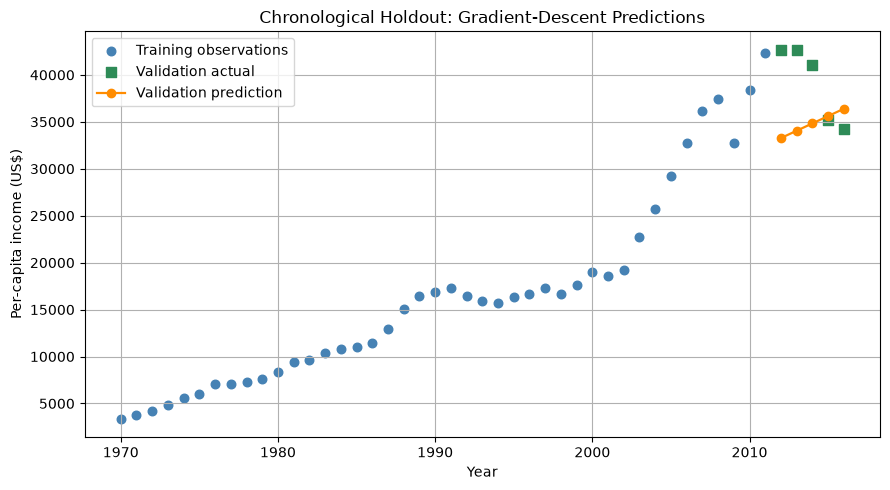

In [10]:
fig, ax = plt.subplots()
ax.scatter(
    train_df[year_col], train_df[target_col],
    color="steelblue", s=38, label="Training observations",
)
ax.scatter(
    val_df[year_col], y_val,
    color="seagreen", marker="s", s=58, label="Validation actual",
)
ax.plot(
    val_df[year_col], y_val_pred,
    color="darkorange", marker="o", linewidth=1.6, label="Validation prediction",
)
ax.set_title("Chronological Holdout: Gradient-Descent Predictions")
ax.set_xlabel("Year")
ax.set_ylabel("Per-capita income (US$)")
ax.ticklabel_format(style="plain", axis="y")
ax.legend()
plt.tight_layout()
plt.show()

## 10. Refit from scratch on all pre-2020 rows, then predict 2020

After validation, train a fresh model on **all** eligible pre-2020 observations. Recompute the year mean and standard deviation using that full fitting set; do not reuse the holdout scaler, and do not include 2020-or-later rows. Apply this final scaler to year 2020 and pass the transformed value through the newly learned line. This is the requested prediction; it is an extrapolation if the file ends before 2020.

In [11]:
x_all_raw = eligible_df[year_col].to_numpy(dtype=float)
y_all = eligible_df[target_col].to_numpy(dtype=float)
x_mean_final = float(np.mean(x_all_raw))
x_std_final = float(np.std(x_all_raw, ddof=0))
if x_std_final == 0:
    raise ValueError("The final fitting years have no variation, so they cannot be scaled.")
z_all = (x_all_raw - x_mean_final) / x_std_final

final_fit = train_gradient_descent(
    z_all,
    y_all,
    learning_rate=LEARNING_RATE,
    max_epochs=MAX_EPOCHS,
    tolerance=LOSS_TOLERANCE,
)
z_2020 = (2020 - x_mean_final) / x_std_final
predicted_2020 = final_fit["weight"] * z_2020 + final_fit["bias"]

# Translate the standardized-year equation into familiar year units for interpretation.
slope_per_year = final_fit["weight"] / x_std_final
intercept_year_units = final_fit["bias"] - slope_per_year * x_mean_final
intercept_sign = "+" if intercept_year_units >= 0 else "−"

final_loss_history = final_fit["loss_history"]
initial_final_mse = final_loss_history[0]
final_train_mse = final_loss_history[-1]
final_train_drop_pct = 100 * (1 - final_train_mse / initial_final_mse)

print(f"Final fitting rows: {len(eligible_df)} ({eligible_df[year_col].min()}–{eligible_df[year_col].max()})")
print(f"Final scaler mean μ: {x_mean_final:.2f}; standard deviation σ: {x_std_final:.4f}")
print(f"Learned weight w (per scaled-year unit): {final_fit['weight']:,.6f} US$")
print(f"Learned intercept b (at mean year): US$ {final_fit['bias']:,.2f}")
print(
    "Equivalent original-year equation: "
    f"income = {slope_per_year:,.4f} × year {intercept_sign} US$ {abs(intercept_year_units):,.2f}"
)
print(f"Gradient updates: {final_fit['epochs']} (loss tolerance reached: {final_fit['converged']})")
print(f"Training MSE: US$² {initial_final_mse:,.2f} → US$² {final_train_mse:,.2f} ({final_train_drop_pct:.2f}% decrease)")
print("\n" + "=" * 58)
print(f"Predicted Canada per-capita income in 2020: US$ {predicted_2020:,.2f}")
print("=" * 58)
if len(observed_2020):
    print("An observed 2020 row exists, but it was excluded from both fitting stages:")
    display(observed_2020[[year_col, target_col]])
else:
    print("No 2020 observation is present in the CSV; the 2020 value is a forecast.")

Final fitting rows: 47 (1970–2016)
Final scaler mean μ: 1993.00; standard deviation σ: 13.5647
Learned weight w (per scaled-year unit): 11,237.846929 US$
Learned intercept b (at mean year): US$ 18,920.14
Equivalent original-year equation: income = 828.4651 × year − US$ 1,632,210.74
Gradient updates: 175 (loss tolerance reached: True)
Training MSE: US$² 499,723,531.64 → US$² 15,462,739.06 (96.91% decrease)

Predicted Canada per-capita income in 2020: US$ 41,288.69
No 2020 observation is present in the CSV; the 2020 value is a forecast.


## 11. Inspect the loss curves and convergence

Plot MSE after each update for the holdout-training run and the final refit. The vertical axis is logarithmic so early large reductions and the later plateau are both visible. The final training MSE does not have to reach zero: real economic observations do not fall exactly on a straight line. We also count any meaningful loss increases, which would suggest divergence or an overly large learning rate.

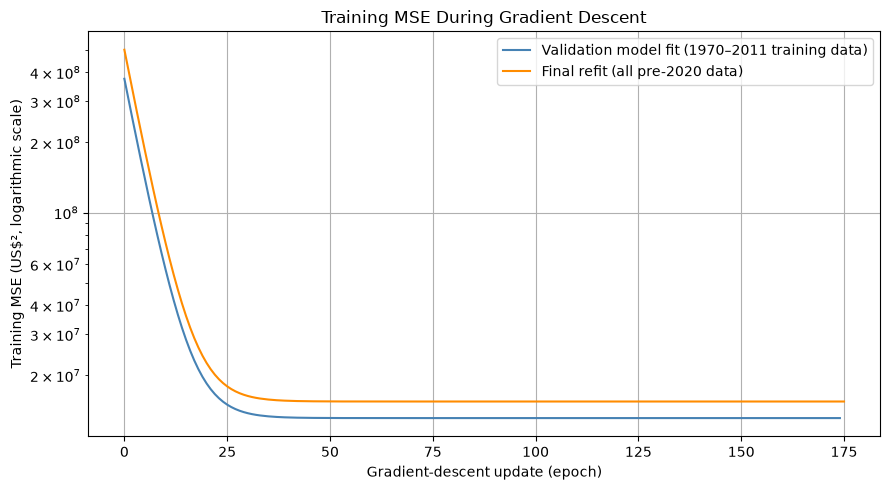

Validation model: 174 updates; MSE 375,052,297.25 → 13,127,064.60; meaningful increases = 0.
Final refit: 175 updates; MSE 499,723,531.64 → 15,462,739.06; meaningful increases = 0.


In [12]:
fig, ax = plt.subplots()
ax.semilogy(
    np.arange(len(validation_loss_history)),
    validation_loss_history,
    color="steelblue",
    label="Validation model fit (1970–2011 training data)",
)
ax.semilogy(
    np.arange(len(final_loss_history)),
    final_loss_history,
    color="darkorange",
    label="Final refit (all pre-2020 data)",
)
ax.set_title("Training MSE During Gradient Descent")
ax.set_xlabel("Gradient-descent update (epoch)")
ax.set_ylabel("Training MSE (US$², logarithmic scale)")
ax.legend()
plt.tight_layout()
plt.show()

for label, history in (
    ("Validation model", validation_loss_history),
    ("Final refit", final_loss_history),
):
    meaningful_increases = int(np.sum(np.diff(history) > 1e-10))
    print(
        f"{label}: {len(history) - 1} updates; "
        f"MSE {history[0]:,.2f} → {history[-1]:,.2f}; "
        f"meaningful increases = {meaningful_increases}."
    )

### Plot the final fitted line and the 2020 prediction

Use the final model only. The historical points in the fit are pre-2020 rows; the line extends beyond the observed range to show how 2020 is extrapolated. If an actual 2020 observation is present in another version of the file, the code marks it separately after the prediction and never includes it in training.

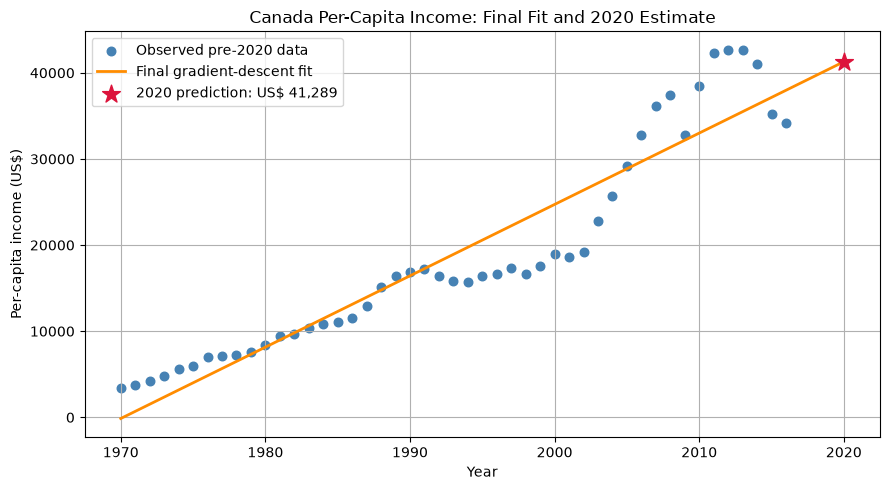

In [13]:
line_years = np.linspace(float(eligible_df[year_col].min()), 2020, 300)
line_scaled_years = (line_years - x_mean_final) / x_std_final
line_income = final_fit["weight"] * line_scaled_years + final_fit["bias"]

fig, ax = plt.subplots()
ax.scatter(
    eligible_df[year_col], eligible_df[target_col],
    color="steelblue", s=38, label="Observed pre-2020 data",
)
ax.plot(
    line_years, line_income,
    color="darkorange", linewidth=2,
    label="Final gradient-descent fit",
)
ax.scatter(
    [2020], [predicted_2020],
    color="crimson", marker="*", s=180, zorder=5,
    label=f"2020 prediction: US$ {predicted_2020:,.0f}",
)
if len(observed_2020):
    ax.scatter(
        observed_2020[year_col], observed_2020[target_col],
        color="black", marker="x", s=80, zorder=6,
        label="Observed 2020 (not used for fitting)",
    )
ax.set_title("Canada Per-Capita Income: Final Fit and 2020 Estimate")
ax.set_xlabel("Year")
ax.set_ylabel("Per-capita income (US$)")
ax.ticklabel_format(style="plain", axis="y")
ax.legend()
plt.tight_layout()
plt.show()

## 12. Results at a glance

Collect the holdout metrics, both training-loss endpoints, the final original-year equation, and the answer in one place. These values are calculated from the variables above, not typed in as model results.

In [14]:
print("ASSIGNMENT 2 / TASK 1 — RESULTS")
print("-" * 68)
print(f"Rows used for final fit       : {len(eligible_df)} ({eligible_df[year_col].min()}–{eligible_df[year_col].max()})")
print(f"Chronological validation     : {val_df[year_col].min()}–{val_df[year_col].max()} ({len(val_df)} rows)")
print(f"Validation MAE / RMSE        : US$ {mae:,.2f} / US$ {rmse:,.2f}")
print(f"Validation R²                : {r2:.4f}")
print(f"Validation-fit MSE           : {initial_validation_train_mse:,.2f} → {final_validation_train_mse:,.2f}")
print(f"Final-refit MSE              : {initial_final_mse:,.2f} → {final_train_mse:,.2f}")
print(f"Final-refit epochs            : {final_fit['epochs']} (converged: {final_fit['converged']})")
print(f"Equivalent slope             : US$ {slope_per_year:,.2f} per year")
print(f"2020 prediction              : US$ {predicted_2020:,.2f}")
print("-" * 68)

ASSIGNMENT 2 / TASK 1 — RESULTS
--------------------------------------------------------------------
Rows used for final fit       : 47 (1970–2016)
Chronological validation     : 2012–2016 (5 rows)
Validation MAE / RMSE        : US$ 5,364.34 / US$ 6,417.59
Validation R²                : -2.0116
Validation-fit MSE           : 375,052,297.25 → 13,127,064.60
Final-refit MSE              : 499,723,531.64 → 15,462,739.06
Final-refit epochs            : 175 (converged: True)
Equivalent slope             : US$ 828.47 per year
2020 prediction              : US$ 41,288.69
--------------------------------------------------------------------


## Conclusion

**Answer:** this from-scratch Gradient Descent model estimates Canada's 2020 per-capita income at **US$ 41,288.69**.

- The file contains **47 annual observations (1970–2016)** with two columns, no missing values, no duplicate rows/years, and no gaps in the year sequence. The input is `year`; the target is per-capita income in US dollars. No valid observations were discarded.
- The chronological validation set is **2012–2016**. Its metrics are **MAE US$ 5,364.34**, **RMSE US$ 6,417.59**, and **R² −2.0116**. The negative R² means this simple straight line predicts this holdout worse than using the holdout mean; the recent plateau and decline explain why extrapolating the earlier trend is difficult.
- On the final pre-2020 refit, the MSE falls from **US$² 499,723,531.64** to **US$² 15,462,739.06** over **175 updates** (a **96.91%** decrease). It levels off at a non-zero value because the observations are not exactly linear. The finite-loss and loss-increase checks pass.
- **Limitations:** 2020 lies beyond the observed 1970–2016 range, so this is an extrapolation of a one-feature linear trend, not an observed 2020 value or a causal forecast. The model cannot learn a later structural change from data it has never seen.
- **Independent sanity check:** Assignment 1's displayed prediction was also about US$41,288.69. This notebook's result is newly learned by its own Gradient Descent updates; no Assignment 1 coefficients or fitted model were used.